# 09 Market Regime Analysis

训练期拟合三类 K-Means 状态并冻结；比较各模型在牛、震荡、熊状态的表现。共同日期仅作事后诊断。


In [1]:
import json, hashlib, platform, sys
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, balanced_accuracy_score, accuracy_score, f1_score, r2_score
ROOT = Path.cwd().resolve()
assert (ROOT / '01_data_preprocessing.ipynb').is_file()
FEATURES = ['return_1d','return_5d','return_20d','volatility_20d','intraday_return','intraday_range']

def read_frame(path):
    f = pd.read_csv(path, index_col='signal_date', float_precision='round_trip')
    f.index = pd.to_datetime(f.index)
    for c in ['trade_date','settle_date']:
        if c in f: f[c] = pd.to_datetime(f[c])
    assert f.index.is_unique and f.index.is_monotonic_increasing
    return f

def write_json(path, obj):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def new_output(name):
    out = ROOT / 'output' / 'fusion' / name / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
    out.mkdir(parents=True)
    write_json(out/'environment.json', {'python':sys.version,'executable':sys.executable,'numpy':np.__version__,'pandas':pd.__version__})
    inputs = list((ROOT/'data/features').glob('*.csv')) + list((ROOT/'data/processed').glob('*.csv'))
    write_json(out/'fingerprints.json', {str(f.relative_to(ROOT)):hashlib.sha256(f.read_bytes()).hexdigest() for f in inputs})
    return out

def complete_run(name):
    runs = [p for p in (ROOT/'output'/name).iterdir() if (p/'status.json').exists() and json.loads((p/'status.json').read_text())['status']=='completed']
    return sorted(runs)[-1]

def training_folder(run, arm):
    return sorted((run/arm).glob('train_*'))[-1]

def regression_scores(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return {'n':len(y),'mae_bp':np.mean(abs(y-p))*10000,'rmse_bp':np.sqrt(np.mean((y-p)**2))*10000,
            'r2':r2_score(y,p) if len(y)>1 and np.var(y)>0 else np.nan,'direction_accuracy':np.mean((y>0)==(p>0))}


In [2]:
OUT=new_output('09_regime')
MLP_DIR = ROOT/json.loads((ROOT/'output/fusion/mlp_latest.json').read_text())['path']
REG_RUN = ROOT/json.loads((MLP_DIR/'config.json').read_text())['source_run']
CLS_RUN = complete_run('classification_comparison')
SAMPLES = {t:read_frame(ROOT/f'data/features/{t}_samples.csv') for t in ['classification','regression']}
PRED = {}; THRESHOLDS = {}; META = {}
for name,run,arm,task in [('Class A',CLS_RUN,'baseline','classification'),('Class B',CLS_RUN,'final','classification'),('Regression XGB',REG_RUN,'baseline','regression'),('Ridge',REG_RUN,'final','regression')]:
    train=training_folder(run,arm)
    selected=json.loads((train/'selected.json').read_text())
    PRED[name]={s:read_frame(train/f'{s}_predictions.csv') for s in ['train','val']}
    PRED[name]['test']=read_frame(run/arm/'test_predictions.csv')
    THRESHOLDS[name]=selected.get('threshold',.002)
    META[name]={'task':task,'train_mean':selected['train_mean'],'train_median':selected['train_median'],'source_run':str(run.relative_to(ROOT))}
    for s,f in PRED[name].items():
        sample=SAMPLES[task].loc[f.index]
        for col in ['trade_date','settle_date']: pd.testing.assert_series_equal(f[col],sample[col])
        f['target_return']=sample.target_return
        f['target_class']=sample.target_class.astype(int)
        assert (f.index<f.trade_date).all() and (f.trade_date<f.settle_date).all()
PRED['MLP']={s:read_frame(MLP_DIR/f'{s}_predictions.csv') for s in ['train','val','test']}
THRESHOLDS['MLP']=.002
META['MLP']={**META['Ridge'],'source_run':str(MLP_DIR.relative_to(ROOT))}
prices=pd.read_csv(ROOT/'data/processed/sp500_clean.csv',parse_dates=['date']).set_index('date')
for name,parts in PRED.items():
    for s,f in parts.items():
        expected=prices.open.reindex(f.settle_date).to_numpy()/prices.open.reindex(f.trade_date).to_numpy()-1
        np.testing.assert_allclose(f.target_return,expected,atol=1e-14)

def trading_scores(h):
    r=h.net_return; std=r.std(ddof=1)
    return {'n':len(h),'total_return':np.prod(1+r)-1,'max_drawdown':-h.drawdown.min(),
            'sharpe':np.sqrt(252)*r.mean()/std if len(h)>1 and std>0 else np.nan,
            'trades':int((h.entry_turnover>0).sum()+(h.exit_turnover>0).sum()),'turnover':h.turnover.sum(),
            'add_day_fraction':h.add_day.mean(),'holding_time_fraction':(h.position>0).mean(),'average_position':h.position.mean()}


,momentum_5,momentum_20,momentum_60,trend_20,trend_60,volatility_20,drawdown_60,volume_ratio,range_20,n
state,,,,,,,,,,
Bear,-0.029565,-0.115569,-0.204065,-0.058398,-0.138289,0.034800,-0.229933,0.066768,0.040287,176
Bull,0.008392,0.026049,0.051943,0.013102,0.030060,0.008346,-0.013735,-0.007074,0.010846,4096
Sideways,-0.011539,-0.029107,-0.039276,-0.016572,-0.030169,0.013404,-0.078630,0.030773,0.017056,1708


Unified training cutoff: 2020-11-11 00:00:00


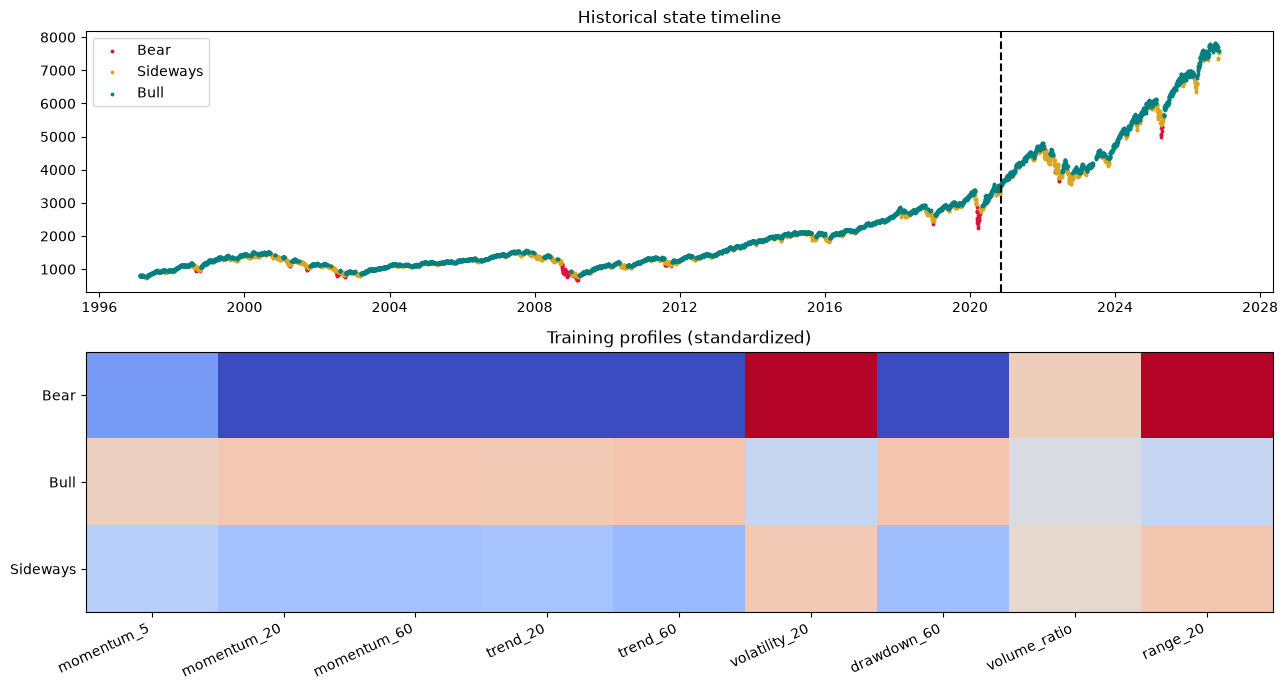

state,Bear,Sideways,Bull
state,,,
Bear,0.848168,0.151832,0.00000
Sideways,0.014085,0.855755,0.13016
Bull,0.000000,0.051390,0.94861


,count,mean,median,max
state,,,,
Bear,29,6.586207,2.0,64
Bull,270,19.322222,5.0,312
Sideways,297,6.932660,3.0,64


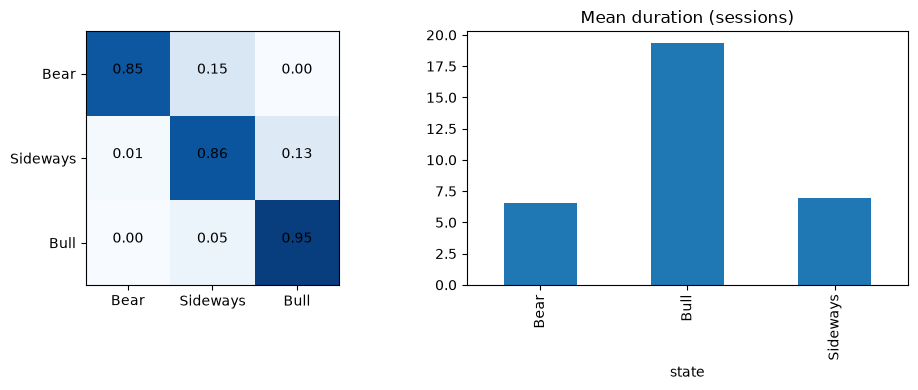

In [3]:
from sklearn.cluster import KMeans
TRADING_DIR=ROOT/json.loads((ROOT/'output/fusion/trading_latest.json').read_text())['path']
source=json.loads((TRADING_DIR/'sources.json').read_text())
assert source=={'classification':str(CLS_RUN.relative_to(ROOT)),'regression':str(REG_RUN.relative_to(ROOT)),'mlp':str(MLP_DIR.relative_to(ROOT))}
cutoff=min(p['train'].index.max() for p in PRED.values())  # Use the earliest model training cutoff
assert cutoff < min(p['val'].index.min() for p in PRED.values())
c=prices.close;sf=pd.DataFrame(index=prices.index)
for n in [5,20,60]:sf[f'momentum_{n}']=c.pct_change(n)
for n in [20,60]:sf[f'trend_{n}']=c/c.rolling(n).mean()-1
sf['volatility_20']=c.pct_change().rolling(20).std()
sf['drawdown_60']=c/c.rolling(60).max()-1
sf['volume_ratio']=prices.volume/prices.volume.rolling(20).mean()-1
sf['range_20']=((prices.high-prices.low)/c).rolling(20).mean()
sf=sf.replace([np.inf,-np.inf],np.nan).dropna();fit=sf.loc[:cutoff]
scaler=StandardScaler().fit(fit);km=KMeans(n_clusters=3,n_init=20,random_state=42).fit(scaler.transform(fit))  # Fit regime scaling before validation dates
train_label=pd.Series(km.labels_,index=fit.index)
order=fit.groupby(train_label).momentum_60.mean().sort_values().index  # Name clusters by train-only momentum
names=dict(zip(map(int,order),['Bear','Sideways','Bull']))
states=pd.Series([names[i] for i in km.predict(scaler.transform(sf))],index=sf.index,name='state')  # Freeze clustering before assigning later states
profile=fit.assign(state=train_label.map(names)).groupby('state').mean();profile['n']=train_label.map(names).value_counts()
profile.to_csv(OUT/'training_state_profile.csv');display(profile)
states.to_csv(OUT/'states.csv')
joblib.dump({'scaler':scaler,'kmeans':km,'names':names},OUT/'regime.joblib')
loaded=joblib.load(OUT/'regime.joblib');np.testing.assert_array_equal(km.predict(scaler.transform(sf)),loaded['kmeans'].predict(loaded['scaler'].transform(sf)))
write_json(OUT/'config.json',{'source':'material4 reference design reimplementation','cutoff':cutoff,'train_n':len(fit),'features':list(sf.columns),'seed':42,'k':3,'n_init':20,'naming':'training momentum_60 ascending','sources':source})
print('Unified training cutoff:',cutoff)
fig,axes=plt.subplots(2,1,figsize=(13,7))
for name,color in [('Bear','crimson'),('Sideways','goldenrod'),('Bull','teal')]:
 idx=states.index[states==name];axes[0].scatter(idx,c.reindex(idx),s=3,color=color,label=name)
axes[0].axvline(cutoff,color='black',ls='--');axes[0].legend();axes[0].set_title('Historical state timeline')
prof=fit.assign(state=train_label.map(names)).groupby('state').mean()
axes[1].imshow(scaler.transform(prof),aspect='auto',cmap='coolwarm',vmin=-2,vmax=2)
axes[1].set_yticks(range(3),prof.index);axes[1].set_xticks(range(len(sf.columns)),sf.columns,rotation=25,ha='right')
axes[1].set_title('Training profiles (standardized)');fig.tight_layout();fig.savefig(OUT/'timeline_profiles.png');display(fig);plt.close(fig)
previous_state=states.reindex(prices.index).shift().reindex(states.index)
trans=pd.crosstab(previous_state,states).reindex(index=['Bear','Sideways','Bull'],columns=['Bear','Sideways','Bull'],fill_value=0)
trans=trans.div(trans.sum(axis=1),axis=0);trans.to_csv(OUT/'transition_matrix.csv');display(trans)
breaks=states.ne(previous_state)
segments=states.groupby(breaks.cumsum()).agg(['first','size']);segments.columns=['state','sessions'];segments.index.name=None
duration=segments.groupby('state').sessions.agg(['count','mean','median','max']);duration.to_csv(OUT/'state_duration.csv');display(duration)
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].imshow(trans,vmin=0,vmax=1,cmap='Blues')
axes[0].set_xticks(range(3),trans.columns);axes[0].set_yticks(range(3),trans.index)
for i in range(3):
 for j in range(3):axes[0].text(j,i,f'{trans.iloc[i,j]:.2f}',ha='center')
duration['mean'].plot.bar(ax=axes[1],title='Mean duration (sessions)');fig.tight_layout();fig.savefig(OUT/'transition_duration.png');display(fig);plt.close(fig)


### Samples and prediction metrics

少于 20 个样本或分类仅一类时，相应指标记为 N/A。


In [4]:
HIST={}
for path in TRADING_DIR.glob('*.csv'):
 if path.name in ['trading_metrics.csv','cost_sensitivity.csv','prediction_metrics.csv','ddqn_seed_metrics.csv','ddqn_seed_mean_std.csv','ddqn_validation_search.csv','regression_threshold_search.csv']:continue
 f=read_frame(path)
 if 'net_return' in f:HIST[path.stem.replace('_',' ')]=f
common=set.intersection(*[set(f.index) for f in HIST.values()],*[set(p['test'].index) for p in PRED.values()],set(states.index))  # Compare models on identical signal dates
common=pd.DatetimeIndex(sorted(common),name='signal_date');assert len(common)>0
exclusions=pd.DataFrame([{'model_or_strategy':n,'original_n':len(f),'common_n':len(common),'excluded':len(f)-len(common),'first_common':common.min(),'last_common':common.max()} for n,f in [(n,p['test']) for n,p in PRED.items()]+list(HIST.items())])
exclusions.to_csv(OUT/'common_date_exclusions.csv',index=False);display(exclusions)
rows=[]
for period in ['original_test','common_dates_posthoc']:
 for name,parts in PRED.items():
  f=parts['test'].copy()
  if period=='common_dates_posthoc':f=f.loc[common]
  f=f.join(states)
  for state in ['Bear','Sideways','Bull']:
   g=f.loc[f.state==state];y=g.target_return;p=g.prediction;label=g.target_class
   support={'n':len(g),'first_signal':g.index.min(),'last_signal':g.index.max(),'class_0':int((label==0).sum()),'class_1':int((label==1).sum()),'positive_return_fraction':(y>0).mean()}
   task=META[name]['task'];reason='N/A: fewer than 20 samples' if len(g)<20 else ''  # Avoid unstable small-sample metrics
   if task=='classification':
    valid=len(g)>=20 and label.nunique()==2
    if len(g)>=20 and label.nunique()<2:reason='N/A: only one label class'
    pred=p>=THRESHOLDS[name];scores={k:np.nan for k in ['roc_auc','ap','accuracy','balanced_accuracy','f1']}
    if valid:scores.update(roc_auc=roc_auc_score(label,p),ap=average_precision_score(label,p),accuracy=accuracy_score(label,pred),balanced_accuracy=balanced_accuracy_score(label,pred),f1=f1_score(label,pred,zero_division=0))
    majority=int(parts['train'].target_class.mean()>=.5);scores['train_majority_accuracy']=(label==majority).mean() if len(g) else np.nan
   else:
    scores={k:np.nan for k in ['mae_bp','rmse_bp','r2','direction_accuracy']}
    if len(g)>=20:scores.update(regression_scores(y,p));scores.pop('n',None)
    for baseline in ['train_mean','train_median']:
     if len(g)>=20:
      b=regression_scores(y,np.repeat(META[name][baseline],len(g)));scores.update({baseline+'_'+k:v for k,v in b.items() if k!='n'})
    scores['always_up_direction']=(y>0).mean() if len(g) else np.nan
   rows.append({'period':period,'model':name,'task':task,'state':state,**support,**scores,'note':reason})
pred_table=pd.DataFrame(rows);pred_table.to_csv(OUT/'prediction_by_state.csv',index=False);display(pred_table.fillna('N/A'))


,model_or_strategy,original_n,common_n,excluded,first_common,last_common
0,Class A,449,449,0,2025-01-29,2026-11-10
1,Class B,449,449,0,2025-01-29,2026-11-10
2,Regression XGB,752,449,303,2025-01-29,2026-11-10
3,Ridge,752,449,303,2025-01-29,2026-11-10
4,MLP,752,449,303,2025-01-29,2026-11-10
5,Buy hold,752,449,303,2025-01-29,2026-11-10
6,Class A,449,449,0,2025-01-29,2026-11-10
7,Class B,449,449,0,2025-01-29,2026-11-10
8,DDQN seed 42,752,449,303,2025-01-29,2026-11-10
9,DDQN seed 43,752,449,303,2025-01-29,2026-11-10


,period,model,task,state,n,first_signal,last_signal,class_0,class_1,positive_return_fraction,roc_auc,ap,accuracy,balanced_accuracy,f1,train_majority_accuracy,note,mae_bp,rmse_bp,r2,direction_accuracy,always_up_direction,train_mean_mae_bp,train_mean_rmse_bp,train_mean_r2,train_mean_direction_accuracy,train_median_mae_bp,train_median_rmse_bp,train_median_r2,train_median_direction_accuracy
0,original_test,Class A,classification,Bear,8,2025-04-04,2025-04-22,4,4,0.500000,N/A,N/A,N/A,N/A,N/A,0.5,N/A: fewer than 20 samples,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
1,original_test,Class A,classification,Sideways,80,2025-02-24,2026-11-10,47,33,0.475000,0.51773,0.465822,0.425,0.506125,0.581818,0.5875,,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
2,original_test,Class A,classification,Bull,361,2025-01-29,2026-11-04,211,150,0.578947,0.553175,0.459417,0.551247,0.532275,0.4375,0.584488,,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
3,original_test,Class B,classification,Bear,8,2025-04-04,2025-04-22,4,4,0.500000,N/A,N/A,N/A,N/A,N/A,0.5,N/A: fewer than 20 samples,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
4,original_test,Class B,classification,Sideways,80,2025-02-24,2026-11-10,47,33,0.475000,0.444874,0.413743,0.4375,0.51225,0.579439,0.5875,,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
5,original_test,Class B,classification,Bull,361,2025-01-29,2026-11-04,211,150,0.578947,0.578989,0.47734,0.578947,0.581027,0.539394,0.584488,,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
6,original_test,Regression XGB,regression,Bear,8,2025-04-04,2025-04-22,4,4,0.500000,N/A,N/A,N/A,N/A,N/A,N/A,N/A: fewer than 20 samples,N/A,N/A,N/A,N/A,0.5,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
7,original_test,Regression XGB,regression,Sideways,108,2024-04-15,2026-11-10,56,52,0.546296,N/A,N/A,N/A,N/A,N/A,N/A,,98.459401,131.33658,-0.002111,0.527778,0.546296,98.399594,131.234872,-0.000559,0.546296,98.098447,131.201727,-0.000054,0.546296
8,original_test,Regression XGB,regression,Bull,636,2023-11-10,2026-11-04,367,269,0.584906,N/A,N/A,N/A,N/A,N/A,N/A,,52.940075,72.437554,-0.001471,0.584906,0.584906,52.8925,72.426862,-0.001175,0.584906,52.572969,72.401668,-0.000479,0.584906
9,original_test,Ridge,regression,Bear,8,2025-04-04,2025-04-22,4,4,0.500000,N/A,N/A,N/A,N/A,N/A,N/A,N/A: fewer than 20 samples,N/A,N/A,N/A,N/A,0.5,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A


### Trading by state

在完整时间线上归因原策略净收益，不构成独立择时策略。


,period,strategy,state,first_signal,last_signal,timeline_n,n,total_return,max_drawdown,sharpe,trades,turnover,add_day_fraction,holding_time_fraction,average_position,note
0,original_test,Buy hold,Bear,2025-04-04,2025-04-22,752,8,N/A,N/A,N/A,0,0.0,0.000000,1.0000,1.0000,N/A: fewer than 20 samples
1,original_test,Buy hold,Sideways,2024-04-15,2026-11-10,752,108,0.061223,0.207472,0.291767,1,1.0,0.000000,1.0000,1.0000,full timeline attribution
2,original_test,Buy hold,Bull,2023-11-10,2026-11-04,752,636,0.421232,0.094533,1.166943,1,1.0,0.001572,1.0000,1.0000,full timeline attribution
3,original_test,Class A,Bear,2025-04-04,2025-04-22,449,8,N/A,N/A,N/A,0,0.0,0.000000,1.0000,1.0000,N/A: fewer than 20 samples
4,original_test,Class A,Sideways,2025-02-24,2026-11-10,449,80,-0.094129,0.197697,-0.551844,8,8.0,0.050000,0.9625,0.9625,full timeline attribution
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,common_dates_posthoc,Ridge,Sideways,2025-02-24,2026-11-10,449,80,-0.060159,0.06487,-0.693627,4,4.0,0.025000,0.0250,0.0250,full timeline attribution
74,common_dates_posthoc,Ridge,Bull,2025-01-29,2026-11-04,449,361,0.0,-0.0,N/A,0,0.0,0.000000,0.0000,0.0000,full timeline attribution
75,common_dates_posthoc,Ridge val threshold,Bear,2025-04-04,2025-04-22,449,8,N/A,N/A,N/A,2,2.0,0.125000,0.2500,0.2500,N/A: fewer than 20 samples
76,common_dates_posthoc,Ridge val threshold,Sideways,2025-02-24,2026-11-10,449,80,-0.060159,0.06487,-0.693627,4,4.0,0.025000,0.0250,0.0250,full timeline attribution


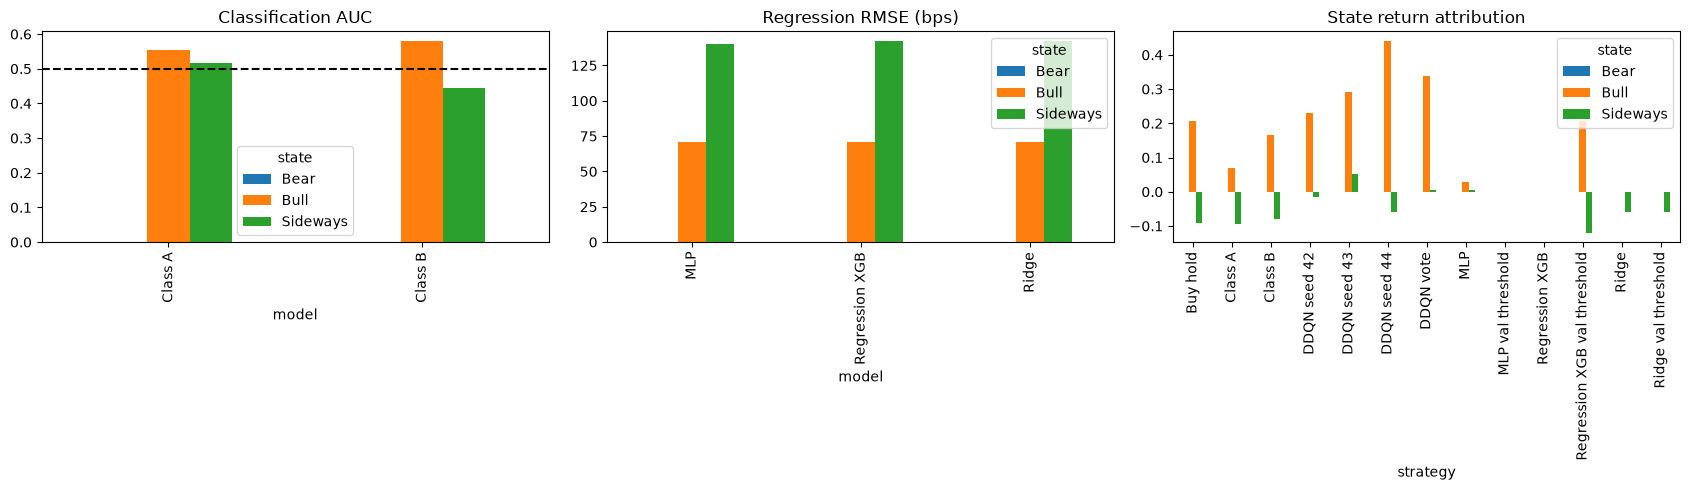

Saved: output/fusion/09_regime/20261124_151855_395553


In [5]:
rows=[]
for period in ['original_test','common_dates_posthoc']:
 for name,h in HIST.items():
  if period=='common_dates_posthoc':
   timeline=prices.index[(prices.index>=common.min()) & (prices.index<=common.max())]
   h=h.reindex(timeline)
   for col in ['net_return','position','turnover','entry_turnover','exit_turnover','add_day']:h[col]=h[col].fillna(0)
  for state in ['Bear','Sideways','Bull']:
   mask=states.reindex(h.index).eq(state)
   if period=='common_dates_posthoc':mask &= h.index.isin(common)
   sub=h.loc[mask];g=h.copy();g['net_return']=h.net_return.where(mask,0.)  # Attribute realized returns on the full calendar
   g['equity']=(1+g.net_return).cumprod();g['drawdown']=g.equity/np.maximum.accumulate(np.r_[1,g.equity])[1:]-1  # Compound masked returns without joining distant dates
   scores=trading_scores(g);scores.update(n=len(sub),turnover=sub.turnover.sum(),trades=int((sub.entry_turnover>0).sum()+(sub.exit_turnover>0).sum()),add_day_fraction=sub.add_day.mean(),holding_time_fraction=(sub.position>0).mean(),average_position=sub.position.mean())
   if len(sub)<20:
    for k in ['total_return','max_drawdown','sharpe']:scores[k]=np.nan
   rows.append({'period':period,'strategy':name,'state':state,'first_signal':sub.index.min(),'last_signal':sub.index.max(),'timeline_n':len(h),**scores,'note':'N/A: fewer than 20 samples' if len(sub)<20 else 'full timeline attribution'})
trade_table=pd.DataFrame(rows);trade_table.to_csv(OUT/'trading_by_state.csv',index=False);display(trade_table.fillna('N/A'))
fig,axes=plt.subplots(1,3,figsize=(17,5))
a=pred_table.query("period=='common_dates_posthoc' and task=='classification'");b=pred_table.query("period=='common_dates_posthoc' and task=='regression'");c=trade_table.query("period=='common_dates_posthoc'")
a.pivot(index='model',columns='state',values='roc_auc').plot.bar(ax=axes[0],title='Classification AUC');axes[0].axhline(.5,color='black',ls='--')
b.pivot(index='model',columns='state',values='rmse_bp').plot.bar(ax=axes[1],title='Regression RMSE (bps)')
c.pivot(index='strategy',columns='state',values='total_return').plot.bar(ax=axes[2],title='State return attribution')
fig.tight_layout();fig.savefig(OUT/'performance_by_state.png');display(fig);plt.close(fig)
write_json(OUT/'verification.json',{'cutoff':cutoff,'fit_before_all_validation':True,'state_reload_exact':True,'common_n':len(common),'original_and_common_separate':True,'noncontinuous_dates_not_compacted':True})
write_json(ROOT/'output/fusion/regime_latest.json',{'path':str(OUT.relative_to(ROOT))})
print('Saved:',OUT.relative_to(ROOT))


状态是历史特征的相对分组，不等于未来行情。样本占比影响指标，稀少状态不作稳定排名。不同任务的准确率不可互换，共同区间仅帮助解释历史差异。


本次共同449日：牛市361、震荡80、熊市8。分类B在牛市AUC约0.579、震荡约0.445。熊市样本不足，缺失柱表示N/A而非零。横轴为状态或策略，回归误差越低越好；状态收益为原策略贡献，不能读成独立状态择时收益。


## 文献对照

[Wang、Lin 和 Mikhelson (2020)](https://doi.org/10.3390/jrfm13120311) 使用滚动 HMM 与因子组合；这里仅诊断冻结的 K-Means 状态。


In [1]:
SECTION='09_regime'
import json, hashlib
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
from IPython.display import display
ROOT = Path.cwd().resolve()
assert (ROOT/'01_data_preprocessing.ipynb').is_file()
LIT_OUT = ROOT/'output/literature'/SECTION/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
LIT_OUT.mkdir(parents=True)
trade_dir=ROOT/json.loads((ROOT/'output/fusion/trading_latest.json').read_text())['path'];path=trade_dir/'trading_metrics.csv';INPUTS=[path];f=pd.read_csv(path);rows=[]
for _,r in f[f.strategy.isin(['Buy hold','DDQN vote'])].iterrows():
    rows.append({'origin':'local full-test context','strategy':r.strategy,'Sharpe':r.sharpe,'max_drawdown':r.max_drawdown,'period':str(r.first_signal)+' to '+str(r.last_signal),'risk_free':'0','cost':'5bps one-way','state_method':'KMeans diagnostic; no regime timing strategy'})
for name,sh,mdd in [('S&P500',-.174,.341),('HMM factor rotation',2.017,.1283)]:
    rows.append({'origin':'paper reported Table4','strategy':name,'Sharpe':sh,'max_drawdown':mdd,'period':'2017-09 to 2020-04','risk_free':'10-year US Treasury yield','cost':'NR','state_method':'HMM daily refit; factor rotation'})
PAPER={'authors':'Matthew Wang; Yi-Hong Lin; Ilya Mikhelson','year':2020,'doi':'10.3390/jrfm13120311','url':'https://mdpi-res.com/d_attachment/jrfm/jrfm-13-00311/article_deploy/jrfm-13-00311.pdf','location':'Table4 PDF p11; Table7 PDF p12; section4.1','not_reproduced':True,'transaction_cost':'not established from inspected text'}
literature_table=pd.DataFrame(rows)

literature_table.to_csv(LIT_OUT/'literature_comparison.csv',index=False,encoding='utf-8-sig')
(LIT_OUT/'extraction.json').write_text(json.dumps({'checked_on':'2026-11-24','paper':PAPER,'table':literature_table.replace({np.nan:None}).to_dict('records'),'input_sha256':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in INPUTS}},ensure_ascii=False,indent=2),encoding='utf-8')
display(literature_table.fillna('N/A'))
print('Saved:',LIT_OUT.relative_to(ROOT))

regime_literature=pd.DataFrame({'paper_state':['Regime 0','Regime 1','Regime 2'],'SP500_unannualized_conditional_Sharpe':[.03488,.06872,-.02504],'local_state_mapping':['not established']*3})
regime_literature.to_csv(LIT_OUT/'paper_state_sharpe.csv',index=False)
display(regime_literature)


,origin,strategy,Sharpe,max_drawdown,period,risk_free,cost,state_method
0,local full-test context,Buy hold,1.294864,0.192470,2023-11-10 to 2026-11-10,0,5bps one-way,KMeans diagnostic; no regime timing strategy
1,local full-test context,DDQN vote,1.984109,0.110724,2023-11-10 to 2026-11-10,0,5bps one-way,KMeans diagnostic; no regime timing strategy
2,paper reported Table4,S&P500,-0.174000,0.341000,2017-09 to 2020-04,10-year US Treasury yield,NR,HMM daily refit; factor rotation
3,paper reported Table4,HMM factor rotation,2.017000,0.128300,2017-09 to 2020-04,10-year US Treasury yield,NR,HMM daily refit; factor rotation


Saved: output\literature\09_regime\20261124_155356_401654


,paper_state,SP500_unannualized_conditional_Sharpe,local_state_mapping
0,Regime 0,0.03488,not established
1,Regime 1,0.06872,not established
2,Regime 2,-0.02504,not established


结论边界：该文支持“按状态检查风险与模型表现”的研究动机，但不能验证本地三状态标签的正确率；本地熊市仅8日，技能指标N/A，不借论文数字补足。
